# Smart Property Price Predictor — Dimensionality Reduction
Weeks 11–12 Hack-O-Week

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

## 1. Load the dataset

In [2]:
data = fetch_california_housing(as_frame=True)
df = data.frame.copy()
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
print("Dataset shape:", df.shape)
print(df.isnull().sum())
df.describe().round(2)

Dataset shape: (20640, 9)
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


## 2. Prepare the features

In [4]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"] * 100000

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

imputer = SimpleImputer(strategy="median")
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(imputer.fit_transform(X_train))
X_test_scaled = scaler.transform(imputer.transform(X_test))

print("Original number of features:", X_train.shape[1])
print("Training samples:", X_train.shape[0])

Original number of features: 8
Training samples: 16512


## 3. Principal Component Analysis (PCA)

PCA creates new features called principal components. The first components capture the largest amount of variance in the data.

In [5]:
pca = PCA()
X_pca = pca.fit_transform(X_train_scaled)

variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

pca_results = pd.DataFrame({
    "Principal Component": np.arange(1, len(variance) + 1),
    "Explained Variance": variance,
    "Cumulative Variance": cumulative_variance
})

pca_results.round(4)

,Principal Component,Explained Variance,Cumulative Variance
0,1,0.2531,0.2531
1,2,0.2340,0.4872
2,3,0.1592,0.6463
3,4,0.1298,0.7761
4,5,0.1255,0.9016
5,6,0.0822,0.9837
6,7,0.0103,0.9941
7,8,0.0059,1.0000


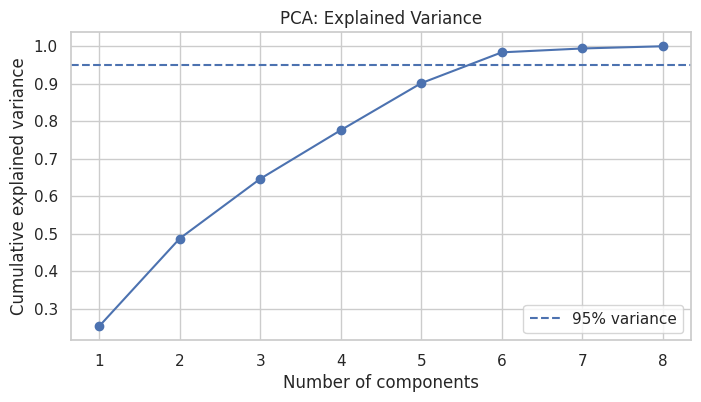

Components needed to retain at least 95% variance: 6


In [6]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker="o")
plt.axhline(0.95, linestyle="--", label="95% variance")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("PCA: Explained Variance")
plt.xticks(range(1, len(variance) + 1))
plt.legend()
plt.show()

n_components_95 = np.argmax(cumulative_variance >= 0.95) + 1
print("Components needed to retain at least 95% variance:", n_components_95)

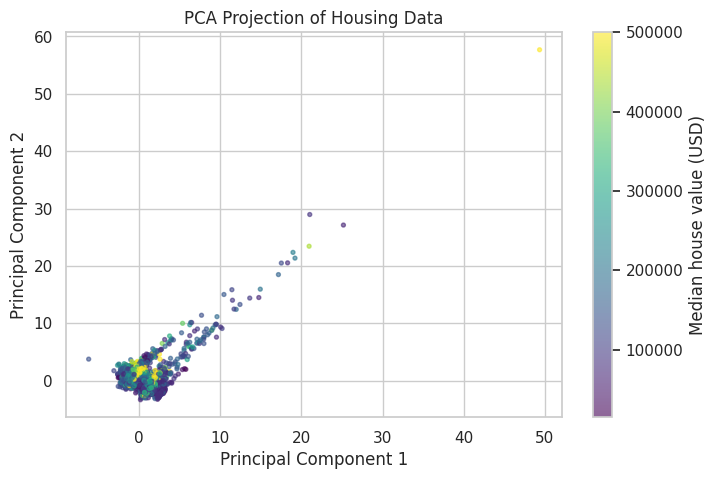

Variance retained by 2 components: 0.4872


In [7]:
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X_pca_2d[:, 0], X_pca_2d[:, 1],
    c=y_train, cmap="viridis", s=8, alpha=0.6
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA Projection of Housing Data")
plt.colorbar(scatter, label="Median house value (USD)")
plt.show()

print("Variance retained by 2 components:", round(pca_2d.explained_variance_ratio_.sum(), 4))

## 4. t-SNE visualization

t-SNE tries to keep nearby samples close together in the 2D map. It is useful for visualizing local groupings, but the axes do not have direct meanings and distances between far-apart clusters should be interpreted cautiously. We use a sample to keep runtime manageable.

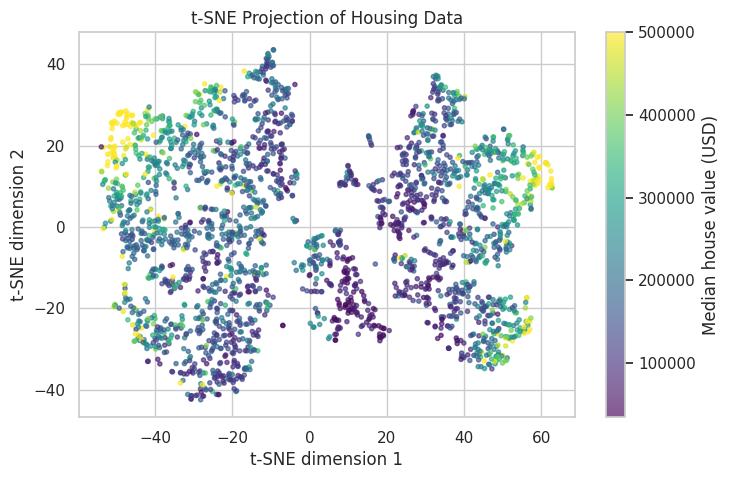

In [8]:
sample_size = min(2500, len(X_train_scaled))
rng = np.random.default_rng(42)
sample_indices = rng.choice(len(X_train_scaled), size=sample_size, replace=False)

X_sample = X_train_scaled[sample_indices]
y_sample = y_train.iloc[sample_indices]

tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)
X_tsne = tsne.fit_transform(X_sample)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1],
    c=y_sample, cmap="viridis", s=9, alpha=0.65
)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE Projection of Housing Data")
plt.colorbar(scatter, label="Median house value (USD)")
plt.show()

## 5. Compare prediction using original features and PCA

PCA can also be used before a prediction model. Here we compare Ridge Regression trained on the original scaled features and on two principal components. The PCA transformation is fitted on the training set only.

In [9]:
pca_model = PCA(n_components=2)
X_train_pca = pca_model.fit_transform(X_train_scaled)
X_test_pca = pca_model.transform(X_test_scaled)

original_model = Ridge(alpha=1.0)
pca_regression_model = Ridge(alpha=1.0)

original_model.fit(X_train_scaled, y_train)
pca_regression_model.fit(X_train_pca, y_train)

original_predictions = original_model.predict(X_test_scaled)
pca_predictions = pca_regression_model.predict(X_test_pca)

comparison = pd.DataFrame([
    {
        "Input": "Original 8 features",
        "MAE": mean_absolute_error(y_test, original_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, original_predictions)),
        "R2 Score": r2_score(y_test, original_predictions)
    },
    {
        "Input": "PCA 2 components",
        "MAE": mean_absolute_error(y_test, pca_predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, pca_predictions)),
        "R2 Score": r2_score(y_test, pca_predictions)
    }
])

comparison.round(2)

,Input,MAE,RMSE,R2 Score
0,Original 8 features,53319.31,74555.67,0.58
1,PCA 2 components,89053.74,113778.51,0.01


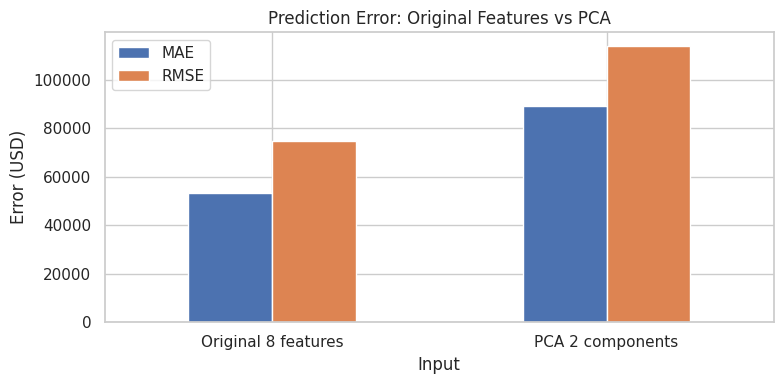

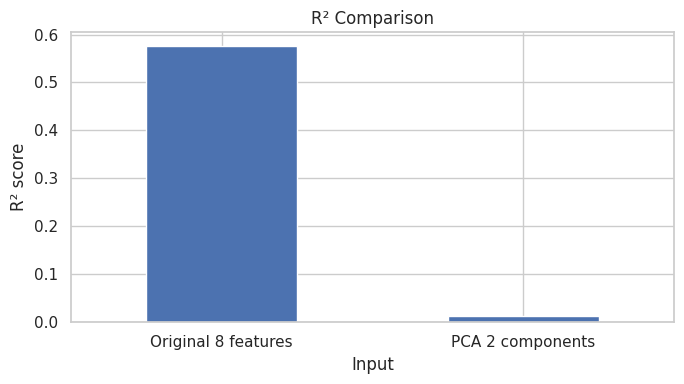

In [10]:
comparison.set_index("Input")[["MAE", "RMSE"]].plot(kind="bar", figsize=(8, 4))
plt.ylabel("Error (USD)")
plt.title("Prediction Error: Original Features vs PCA")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

comparison.set_index("Input")["R2 Score"].plot(kind="bar", figsize=(7, 4))
plt.ylabel("R² score")
plt.title("R² Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Conclusion
PCA reduces the feature space into principal components and shows how much variance those components retain. t-SNE creates a 2D visualization that can reveal local groupings in high-dimensional housing data. The Ridge Regression comparison demonstrates the trade-off between using all original features and using only two PCA components. The dataset describes California census areas, so predictions are area-level estimates rather than current prices for individual homes.